# Low-Light Enhancement

In [2]:
from pathlib import Path
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display


def find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd / "2_low_light_img", *cwd.parents]
    candidates += [parent / "2_low_light_img" for parent in cwd.parents]
    for candidate in candidates:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "report.py").exists():
            return candidate
    raise FileNotFoundError("Nie znaleziono katalogu projektu 2_low_light_img.")


PROJECT_ROOT = find_project_root()
RESULTS_DIR = PROJECT_ROOT / "results"
REPORT_DIR = RESULTS_DIR / "report"

In [4]:
comparison_paths = sorted(REPORT_DIR.glob("comparison_*.png"))

## Tabela metryk


In [7]:
baseline = pd.read_csv(RESULTS_DIR / "baseline.csv")
network = pd.read_csv(RESULTS_DIR / "hvi_cidnet.csv")

common_ids = set(baseline["image_name"]) & set(network["image_name"])
baseline = baseline[baseline["image_name"].isin(common_ids)].sort_values("image_name").reset_index(drop=True)
network = network[network["image_name"].isin(common_ids)].sort_values("image_name").reset_index(drop=True)
n_images = len(baseline)


def fmt(series: pd.Series, decimals: int) -> str:
    return f"{series.mean():.{decimals}f}"


table = pd.DataFrame(
    [
        {
            "Metoda": "Baseline",
            "PSNR": fmt(baseline["PSNR"], 2),
            "SSIM": fmt(baseline["SSIM"], 4),
            "LPIPS": fmt(baseline["LPIPS"], 4),
        },
        {
            "Metoda": "HVI-CIDNet",
            "PSNR": fmt(network["PSNR"], 2),
            "SSIM": fmt(network["SSIM"], 4),
            "LPIPS": fmt(network["LPIPS"], 4),
        },
    ]
)

print(f"Źródło metryk: results/baseline.csv + results/hvi_cidnet.csv | liczba obrazów: {n_images}")
display(table.style.hide(axis="index").set_properties(**{"text-align": "center"}))

Źródło metryk: results/baseline.csv + results/hvi_cidnet.csv | liczba obrazów: 20


Metoda,PSNR,SSIM,LPIPS
Baseline,11.62,0.1361,0.9954
HVI-CIDNet,22.21,0.6485,0.2675


## Wizualizacje

Każda plansza zawiera pełne obrazy (Input, Baseline HE, HVI-CIDNet, Ground Truth),
dwa powiększenia ROI oraz histogramy kanałów RGB.

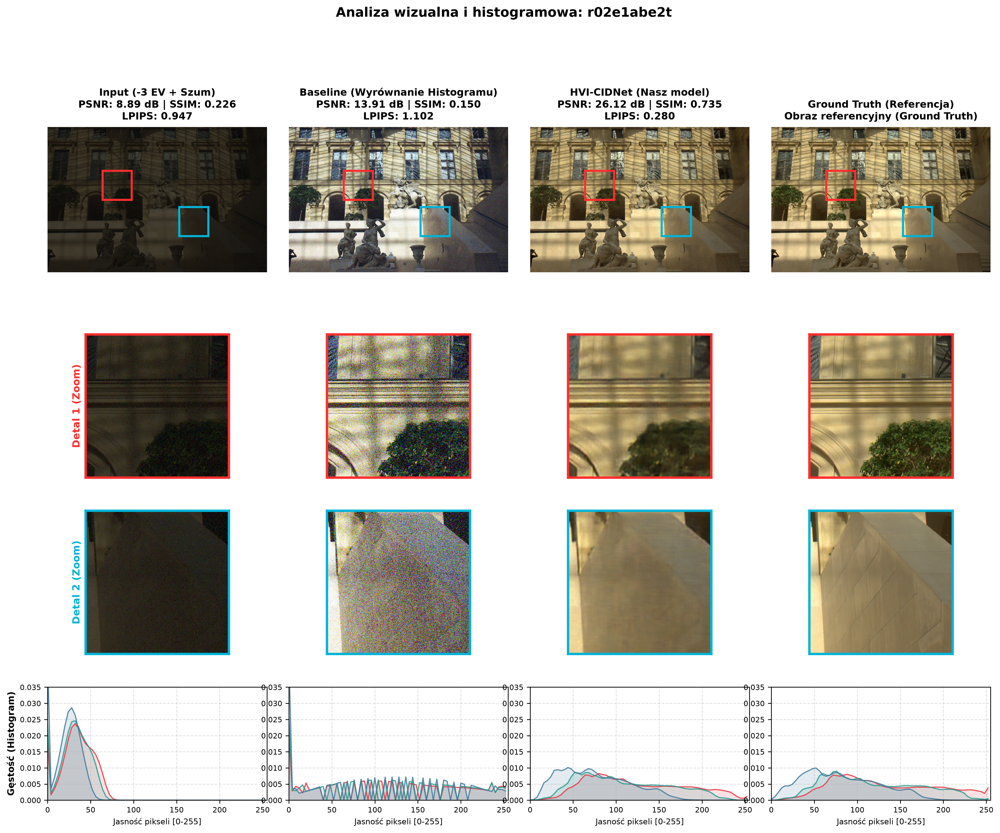

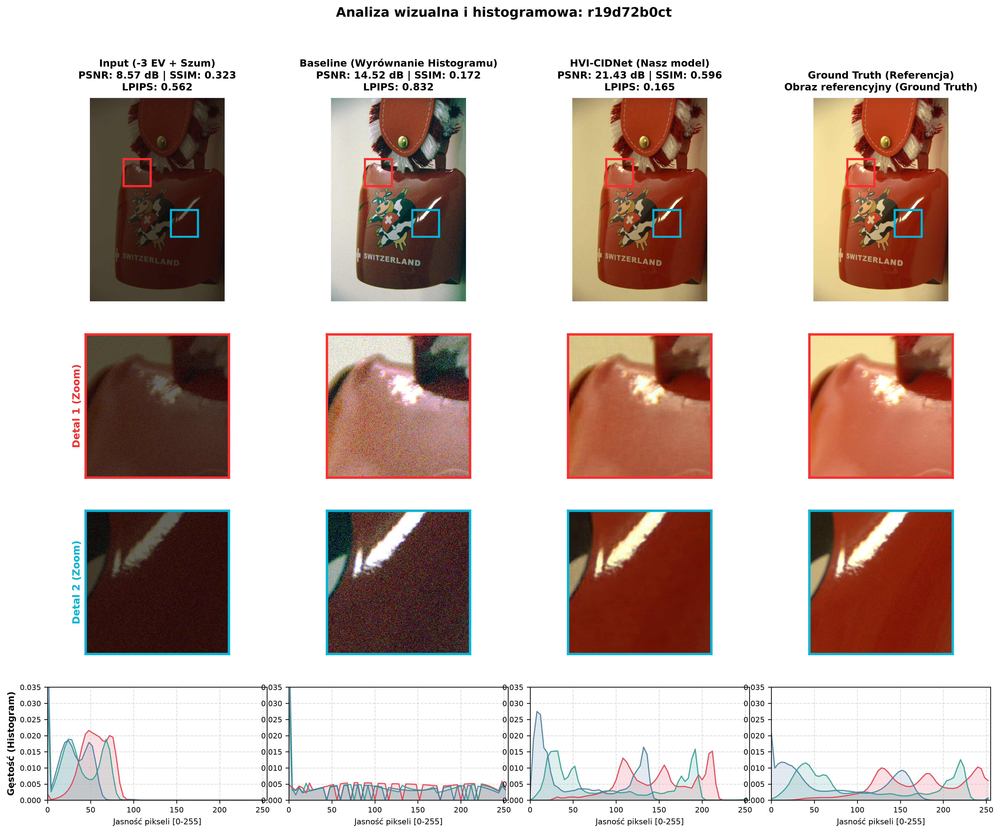

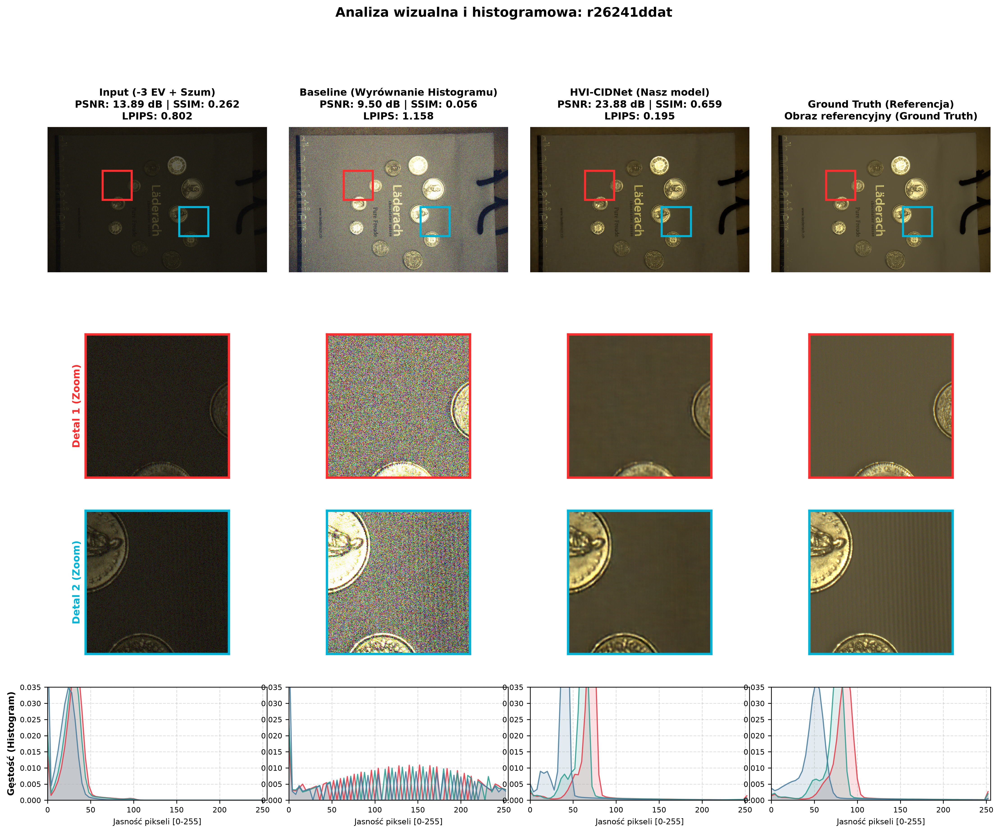

In [9]:
for image_path in comparison_paths:
    image_id = image_path.stem.removeprefix("comparison_")
    display(Image(filename=str(image_path), width=1200))